# Лабораторная работа №1. Сбор, визуализация и анализ данных по графу

Тема: распознавание и перевод жестовых языков (sign language).

In [1]:
import os
import re
import requests
import xml.etree.ElementTree as ET
from collections import Counter
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

import nltk
from nltk.corpus import stopwords, wordnet as wn
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import TfidfVectorizer

for package in ["stopwords", "wordnet", "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(package, quiet=True)

pd.set_option("display.max_colwidth", 100)

## 1–2. Сбор данных

Скачиваем через arXiv API 400 самых свежих статей, в аннотации которых есть "sign language" (с 2020 года). Сохраняем в csv, чтобы при перезапуске не скачивать заново.

In [2]:
def load_arxiv(query, n):
    params = {"search_query": query, "start": 0, "max_results": n,
              "sortBy": "submittedDate", "sortOrder": "descending"}
    response = requests.get("https://export.arxiv.org/api/query", params=params, timeout=120)
    ns = {"a": "http://www.w3.org/2005/Atom"}
    rows = []
    for entry in ET.fromstring(response.content).findall("a:entry", ns):
        rows.append({
            "id": entry.find("a:id", ns).text.split("/abs/")[-1],
            "published": entry.find("a:published", ns).text,
            "title": " ".join(entry.find("a:title", ns).text.split()),
            "authors": ", ".join(a.find("a:name", ns).text for a in entry.findall("a:author", ns)),
            "summary": " ".join(entry.find("a:summary", ns).text.split()),
        })
    return pd.DataFrame(rows)


if os.path.exists("arxiv_sign_language.csv"):
    df = pd.read_csv("arxiv_sign_language.csv")
else:
    df = load_arxiv('abs:"sign language" AND submittedDate:[202001010000 TO 202609242359]', 400)
    df.to_csv("arxiv_sign_language.csv", index=False)

df["published"] = pd.to_datetime(df["published"]).dt.tz_localize(None)
print(df.shape)
print("Период:", df["published"].min().date(), "—", df["published"].max().date())
df.head()

(400, 5)
Период: 2024-06-11 — 2026-09-24


,id,published,title,authors,summary
0,2609.29292v1,2026-09-24 09:27:47,PHOSA: Photorealistic 3D Sign Avatar Modeling and Benchmark,"Haodong Wang, Hezhen Hu, Wengang Zhou, Houqiang Li","In this work, we focus on photorealistic sign avatar modeling, which is crucial for effective communication with the Deaf community and is characterized by complex hand gestures and nuanced facial expressions. To this end, we introduce MVSign, the first multi-view Chinese sign language dataset co-designed with Deaf experts, featuring diverse gestures and rich annotations. For precise SMPL-X annotation, we develop a hybrid fitting pipeline that produces accurate body, hand, and facial parameters and can also be applied to the monocular setting. Building on MVSign, we propose a decoupled sign avatar representation that isolates body, head, and hand components to capture complex articulations, together with a motion-aware sampling strategy to handle motion blur and balance gesture diversity. Extensive experiments demonstrate that our method achieves high-fidelity visual results on MVSign, particularly in detailed hand and facial regions, and generalizes well to in-the-wild monocular sign language videos. Project page: https://naaapi.github.io/PHOSA."
1,2609.25862v1,2026-09-22 08:26:36,Isolated Sign Language Recognition for Icelandic Sign Language: Experiments in a Low-resource Setting,"Finnur Ágúst Ingimundarson, Guðný Björk Þorvaldsdóttir, Mathias Müller, Sarah Ebling","We present the first experiments on isolated sign language recognition (ISLR) for Icelandic Sign Language (ÍTM). We use ÍTM SignWiki, a dataset derived from a bilingual Icelandic--ÍTM online dictionary. It is genuinely low-resource: 1,845 videos cover 849 classes, 86% of which have only two examples, making the full task effectively one-shot recognition across signers. We compare two open-source ISLR frameworks, OpenHands and SPOTER, on three tasks of increasing vocabulary size (22, 117 and 849 classes), and evaluate three pose estimators and two forms of cross-lingual transfer. With ÍTM data alone, SPOTER outperforms OpenHands on all three tasks, and MediaPipe poses give better results than AlphaPose or SDPose. Cross-lingual transfer brings the largest gains: pretraining SPOTER on American Sign Language data before finetuning on ÍTM raises accuracy by 14--24 percentage points, to 72.7%, 47.9% and 22.6% on the three tasks, and multilingual training with data from six other sign languages lifts OpenHands from 1.41% to 28.86% on the full task. Although far from practical use, the results suggest that transfer from better-resourced sign languages is promising for very low-resource ones. We release our adapted versions of both frameworks."
2,2609.21709v1,2026-09-18 12:46:50,SignGPT: Toward LLM-Mediated Sign Language Interaction through Gloss-Free Translation and Generation,"Ronghui Li, Jun Dong, Zhongyuan Hu, Zunnan Xu, Jun Zhou, Liyuan Chen, Shuoling Liu, Jiangpeng Yan, Jie Guo, Xiu Li, Linchao Bao","Large language models (LLMs) provide limited support for sign language interaction. Unifying sign language translation (SLT) and generation (SLG) to enable sign language as both input and output can reduce switching between separate models during sign-text interaction. We present SignGPT, a unified, pose-based framework for gloss-free SLT and SLG. SignGPT integrates part-aware hierarchical representations of body, hand, and facial motion into a shared language model and employs asymmetric multi-token prediction and progressive training for bidirectional modeling. We evaluate SignGPT on How2Sign (ASL) and Phoenix-2014T (DGS) through benchmark comparisons, qualitative analyses, and component ablations. An exploratory study with 12 Deaf ASL signers assesses an LLM-mediated sign-to-sign response pipeline, highlighting the potential of unified modeling to support sign language conversation (SLC)."
3,2609.18772v1,2026-09-16 14:56:51,Zero-Shot Cross-Lingual Recognition of Sign Language Handshape

## 3. Разведочный анализ

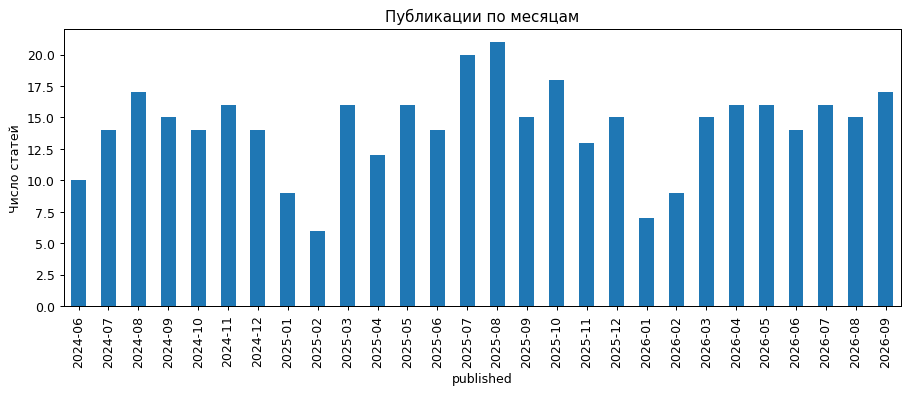

In [3]:
df["published"].dt.to_period("M").value_counts().sort_index().plot(kind="bar", figsize=(12, 4))
plt.title("Публикации по месяцам")
plt.ylabel("Число статей")
plt.show()

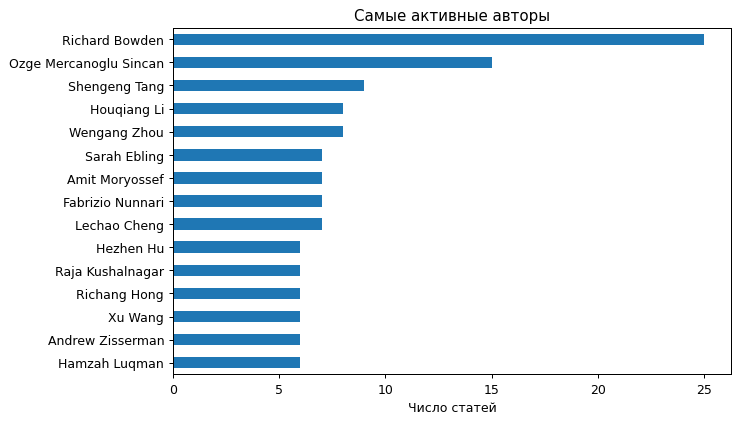

In [4]:
authors = Counter(a for line in df["authors"] for a in line.split(", "))
pd.Series(dict(authors.most_common(15))).sort_values().plot(kind="barh", figsize=(8, 5))
plt.title("Самые активные авторы")
plt.xlabel("Число статей")
plt.show()

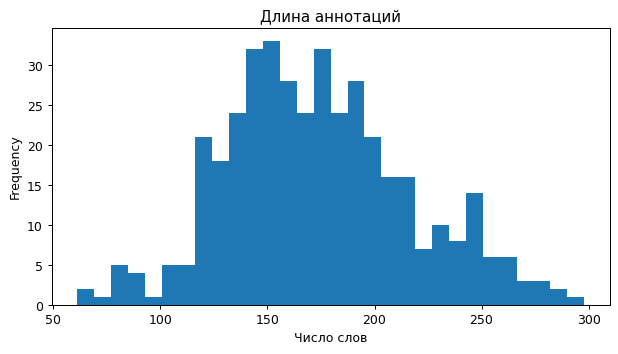

In [5]:
df["summary"].str.split().str.len().plot(kind="hist", bins=30, figsize=(8, 4))
plt.title("Длина аннотаций")
plt.xlabel("Число слов")
plt.show()

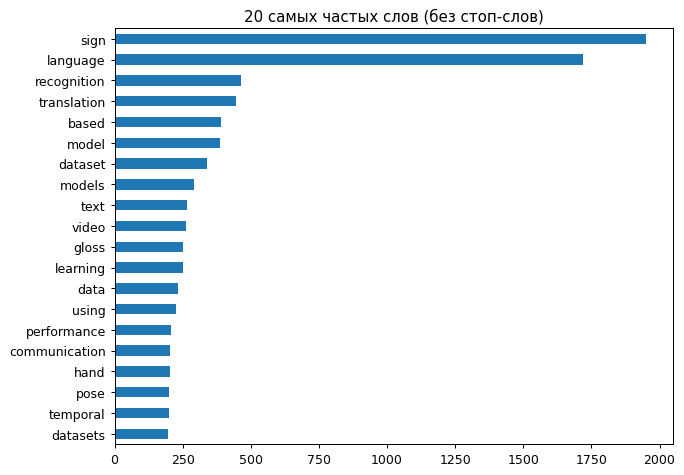

In [6]:
df["text"] = (df["title"] + ". " + df["summary"]).str.lower().str.replace("*", "", regex=False)
all_words = re.findall(r"[a-z]+", " ".join(df["text"]))
stop_words = set(stopwords.words("english"))

top_words = Counter(w for w in all_words if w not in stop_words).most_common(20)
pd.Series(dict(top_words)).sort_values().plot(kind="barh", figsize=(8, 6))
plt.title("20 самых частых слов (без стоп-слов)")
plt.show()

Чаще всего встречаются sign и language — это название темы, поэтому дальше их убираем.

Проверка закона Ципфа: частота слова ~ 1 / ранг, в log-log осях должна получиться прямая с наклоном около -1.

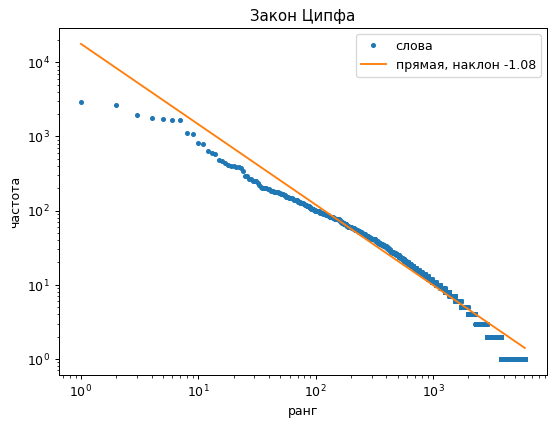

наклон: -1.08


In [7]:
freq = np.array(sorted(Counter(all_words).values(), reverse=True))
rank = np.arange(1, len(freq) + 1)
k, b = np.polyfit(np.log(rank[freq >= 3]), np.log(freq[freq >= 3]), 1)

plt.figure(figsize=(7, 5))
plt.loglog(rank, freq, ".", label="слова")
plt.loglog(rank, np.exp(b) * rank ** k, label=f"прямая, наклон {k:.2f}")
plt.xlabel("ранг")
plt.ylabel("частота")
plt.title("Закон Ципфа")
plt.legend()
plt.show()
print("наклон:", round(k, 2))

Вывод: закон Ципфа выполняется. Точки почти лежат на прямой, наклон -1.08, это близко к -1. Отклонения есть только у самых частых слов (the, and, of) и в хвосте, где много слов встречается по 1–2 раза.

## 4. Ключевые слова

Берём название + аннотацию, оставляем только существительные (чтобы не было глаголов вроде achieve), приводим к начальной форме и убираем стоп-слова, в том числе слова темы (sign, language) и самые общие слова научных статей. Потом по TF-IDF берём 6 лучших слов/словосочетаний (до 3 слов) для каждой статьи.

In [8]:
stop_words |= {"sign", "signer", "language", "paper", "work", "study", "approach", "method", "model",
               "result", "task", "performance", "experiment", "framework", "system", "data", "set",
               "time", "example", "number", "use", "way", "need", "leverage", "state-of-the-art"}
lemmatizer = WordNetLemmatizer()


def is_noun(word):
    # слово бывает существительным или его нет в словаре (например, llm, bleu)
    return bool(wn.synsets(word, pos="n")) or not wn.synsets(word)


def preprocess(text):
    # оставляем подряд идущие существительные как словосочетания, группы разделяем запятой
    tokens = re.findall(r"[a-z]+(?:-[a-z]+)*|[.,;:()]", text.lower())
    phrases, phrase = [], []
    for w, tag in nltk.pos_tag(tokens) + [(".", ".")]:
        w = lemmatizer.lemmatize(w)
        if tag.startswith("NN") and w not in stop_words and len(w) > 2 and is_noun(w):
            phrase.append(w)
        elif phrase:
            phrases.append(" ".join(phrase))
            phrase = []
    return ", ".join(phrases)


df["clean"] = df["text"].apply(preprocess)
df["clean"][0]

'phosa, avatar modeling, benchmark, avatar modeling, communication, deaf community, hand gesture, expression, end, multi-view, deaf expert, gesture, annotation, annotation, pipeline, body, hand, parameter, setting, building, mvsign, avatar representation, body, head, hand component, articulation, sampling strategy, motion blur, balance gesture diversity, mvsign, hand, region, video, project page, http, naaapi, github, phosa'

In [9]:
def ngrams(text):
    # слова и словосочетания из 1–3 слов внутри каждой группы
    result = []
    for phrase in text.split(", "):
        words = phrase.split()
        for n in (1, 2, 3):
            result += [" ".join(words[i:i + n]) for i in range(len(words) - n + 1)]
    return result


vectorizer = TfidfVectorizer(analyzer=ngrams, min_df=3, max_df=0.5)
X = vectorizer.fit_transform(df["clean"])
terms = vectorizer.get_feature_names_out()


def top_keywords(i, n=6):
    row = X[i].toarray().ravel()
    best = np.argsort(-row, kind="stable")[:n]  # stable: при равных весах порядок по алфавиту
    return [terms[j] for j in best if row[j] > 0]


df["keywords"] = [top_keywords(i) for i in range(len(df))]
df[["title", "keywords"]].head(10)

,title,keywords
0,PHOSA: Photorealistic 3D Sign Avatar Modeling and Benchmark,"[avatar, hand, gesture, modeling, body, annotation]"
1,Isolated Sign Language Recognition for Icelandic Sign Language: Experiments in a Low-resource Setting,"[transfer, islr, class, estimator, recognition, percentage point]"
2,SignGPT: Toward LLM-Mediated Sign Language Interaction through Gloss-Free Translation and Generation,"[slg, interaction, modeling, asl, slt, generation]"
3,Zero-Shot Cross-Lingual Recognition of Sign Language Handshapes,"[handshapes, handshape, asl, feature, contact, flexion]"
4,SignMimic: Robust High-Quality Sign Language Motion Generation via Human-Shape-Oblivious Pose Transfer Guidance,"[video, identity, adaptation, motion, video diffusion, news]"
5,Investigating Temporal Motion Features for Pose-to-Text Indian Sign Language Translation,"[motion feature, motion, bleu, score, feature, pose]"
6,Learning Sign Language Recognition under Label Noise: A Study of Noise-Robust Losses for Isolated and Continuous Settings,"[noise, loss, gradient, condition, classification, classifier]"
7,SignRefine: Adapting Foundational Video Models for Sign Language Generation,"[video, video diffusion, video generation, articulation, appearance, generation]"
8,Rethinking Sign Language Translation: The Impact of Signer Dependence on Model Evaluation,"[sentence, evaluation, generalisation, split, test, slt]"
9,RAIDAL: Redundancy-Aware Information Density Active Learning for CTC-Based Continuous Sign Language Recognition,"[acquisition, function, cost, ctc, region, gloss]"


Всего разных ключевых слов: 768


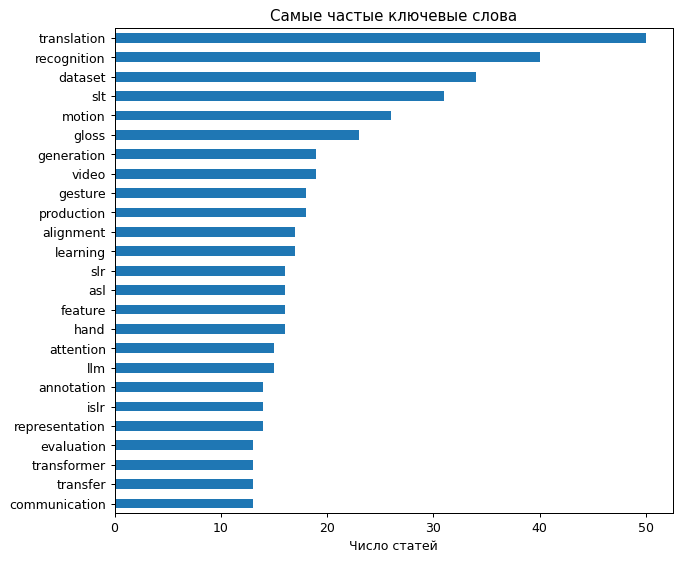

In [10]:
keyword_counts = Counter(k for kws in df["keywords"] for k in kws)
print("Всего разных ключевых слов:", len(keyword_counts))
pd.Series(dict(keyword_counts.most_common(25))).sort_values().plot(kind="barh", figsize=(8, 7))
plt.title("Самые частые ключевые слова")
plt.xlabel("Число статей")
plt.show()

## 5. Граф ключевых слов

Вершины — ключевые слова, ребро — слова встретились у одной статьи, вес — у скольких статей. Слова, которые есть только у одной статьи, не берём.

In [11]:
G = nx.Graph()
for kws in df["keywords"]:
    kws = [k for k in kws if keyword_counts[k] >= 2]
    for a, b in combinations(kws, 2):
        if G.has_edge(a, b):
            G[a][b]["weight"] += 1
        else:
            G.add_edge(a, b, weight=1)

degrees = dict(G.degree())
print("Вершин:", G.number_of_nodes())
print("Рёбер:", G.number_of_edges())
print("Плотность:", round(nx.density(G), 4))
print("Средняя степень:", round(np.mean(list(degrees.values())), 1))

Вершин: 487
Рёбер: 4187
Плотность: 0.0354
Средняя степень: 17.2


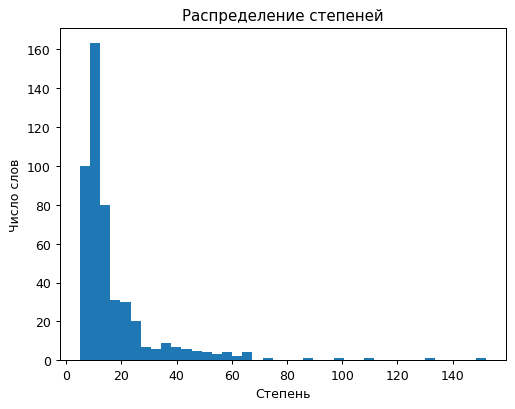

In [12]:
plt.hist(list(degrees.values()), bins=40)
plt.title("Распределение степеней")
plt.xlabel("Степень")
plt.ylabel("Число слов")
plt.show()

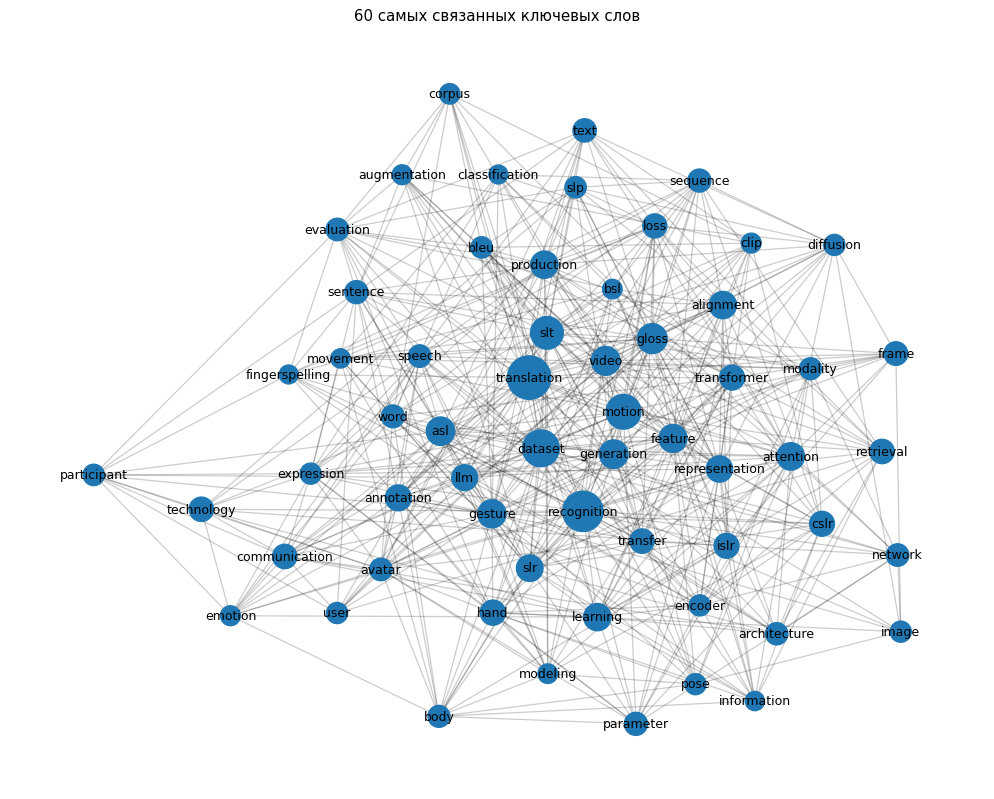

In [13]:
top_nodes = sorted(G, key=degrees.get, reverse=True)[:60]
H = G.subgraph(top_nodes)
pos = nx.spring_layout(H, weight="weight", seed=42, k=0.6, iterations=200)

plt.figure(figsize=(14, 11))
nx.draw_networkx_edges(H, pos, alpha=0.2)
nx.draw_networkx_nodes(H, pos, node_size=[degrees[n] * 8 for n in H])
nx.draw_networkx_labels(H, pos, font_size=10)
plt.title("60 самых связанных ключевых слов")
plt.axis("off")
plt.show()

## 6. Кластеры

In [14]:
communities = nx.community.louvain_communities(G, weight="weight", seed=42)
communities = sorted(communities, key=len, reverse=True)
print("Кластеров:", len(communities))
print("Модулярность:", round(nx.community.modularity(G, communities, weight="weight"), 3))

cluster_of = {w: i for i, c in enumerate(communities) for w in c}
weighted_degree = dict(G.degree(weight="weight"))
pd.DataFrame({
    "размер": [len(c) for c in communities],
    "главные слова": [", ".join(sorted(c, key=lambda w: (-weighted_degree[w], w))[:12]) for c in communities],
})

Кластеров: 9
Модулярность: 0.322


,размер,главные слова
0,99,"translation, slt, gloss, alignment, production, feature, llm, representation, sentence, evaluation, sequence, retrieval"
1,85,"communication, technology, participant, expression, emotion, user, animation, interaction, bangla, people, dhh, isl"
2,61,"motion, video, generation, asl, loss, diffusion, pose, clip, token, bone, appearance, segment"
3,60,"recognition, islr, network, architecture, bsl, accuracy, classification, cnn, training, lstm, fusion, class"
4,56,"dataset, cslr, camera, image, modeling, handshape, technique, datasets, pipeline, setting, face, phoenix"
5,40,"slr, speech, word, modality, movement, description, pre-training, slu, knowledge, jsl, speech recognition, body movement"
6,33,"learning, transfer, encoder, information, transfer learning, fingerspelling, rgb, keypoints, action, machine translation, project, agent"
7,27,"gesture, hand, annotation, avatar, body, parameter, hand gesture, research, label, reconstruction, gesture recognition, signal"
8,26,"attention, frame, transformer, graph, module, bdsl, wlasl, attention module, layer, bdslw, convergence, fps"


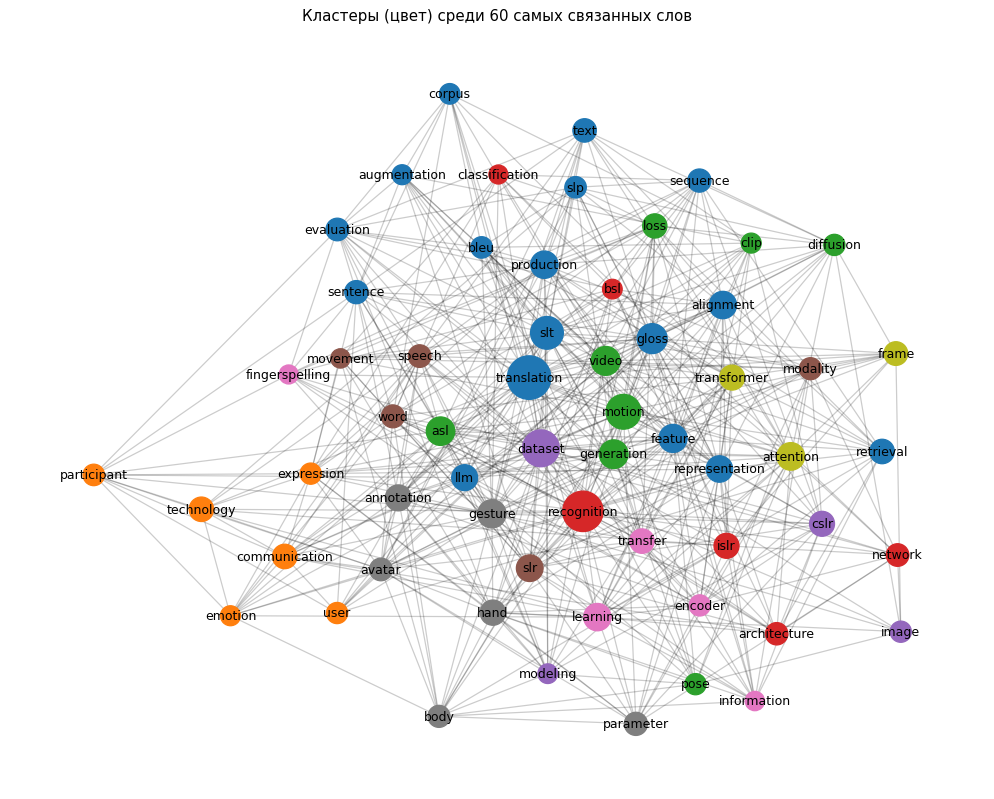

In [15]:
colors = plt.cm.tab10(np.arange(len(communities)) % 10)
plt.figure(figsize=(14, 11))
nx.draw_networkx_edges(H, pos, alpha=0.2)
nx.draw_networkx_nodes(H, pos, node_size=[degrees[n] * 8 for n in H], node_color=[colors[cluster_of[n]] for n in H])
nx.draw_networkx_labels(H, pos, font_size=10)
plt.title("Кластеры (цвет) среди 60 самых связанных слов")
plt.axis("off")
plt.show()

Модулярность 0.32 (больше 0.3), значит кластерная структура есть, хотя кластеры пересекаются через общие слова (translation, recognition, dataset).

Кластеры по смыслу:
- 0 — перевод жестового языка в текст и генерация жестов из текста, обе задачи идут через глоссы (translation, slt, gloss, production, llm);
- 1 — люди и доступность: общение, эмоции, пользовательские исследования (communication, technology, participant, emotion);
- 2 — генерация движений и видео (motion, video, generation, diffusion, pose);
- 3 — распознавание отдельных жестов нейросетями (recognition, islr, cnn, lstm, classification);
- 4 — датасеты и непрерывное распознавание предложений (dataset, cslr, camera, phoenix);
- 5 — речь, мультимодальность и «понимание» жестового языка (speech, modality, pre-training, slu);
- 6 — перенос обучения, дактилология, ключевые точки (transfer learning, fingerspelling, keypoints);
- 7 — жесты рук и тела, 3D-реконструкция, аватары (gesture, hand, body, avatar, reconstruction);
- 8 — архитектуры с вниманием для распознавания слов (attention, transformer, wlasl, bdslw).

## 7. Центральность

In [16]:
centrality = pd.DataFrame({
    "degree": nx.degree_centrality(G),
    "betweenness": nx.betweenness_centrality(G),
    "closeness": nx.closeness_centrality(G),
    "eigenvector": nx.eigenvector_centrality(G, weight="weight", max_iter=1000),
})
pd.DataFrame({m: centrality[m].sort_values(ascending=False).head(10).index for m in centrality}, index=range(1, 11))

,degree,betweenness,closeness,eigenvector
1,translation,translation,translation,translation
2,recognition,recognition,recognition,slt
3,dataset,dataset,dataset,dataset
4,motion,motion,motion,recognition
5,slt,slr,slt,gloss
6,gloss,slt,gloss,alignment
7,video,video,gesture,feature
8,generation,asl,feature,gesture
9,asl,gesture,asl,sentence
10,gesture,generation,attention,motion


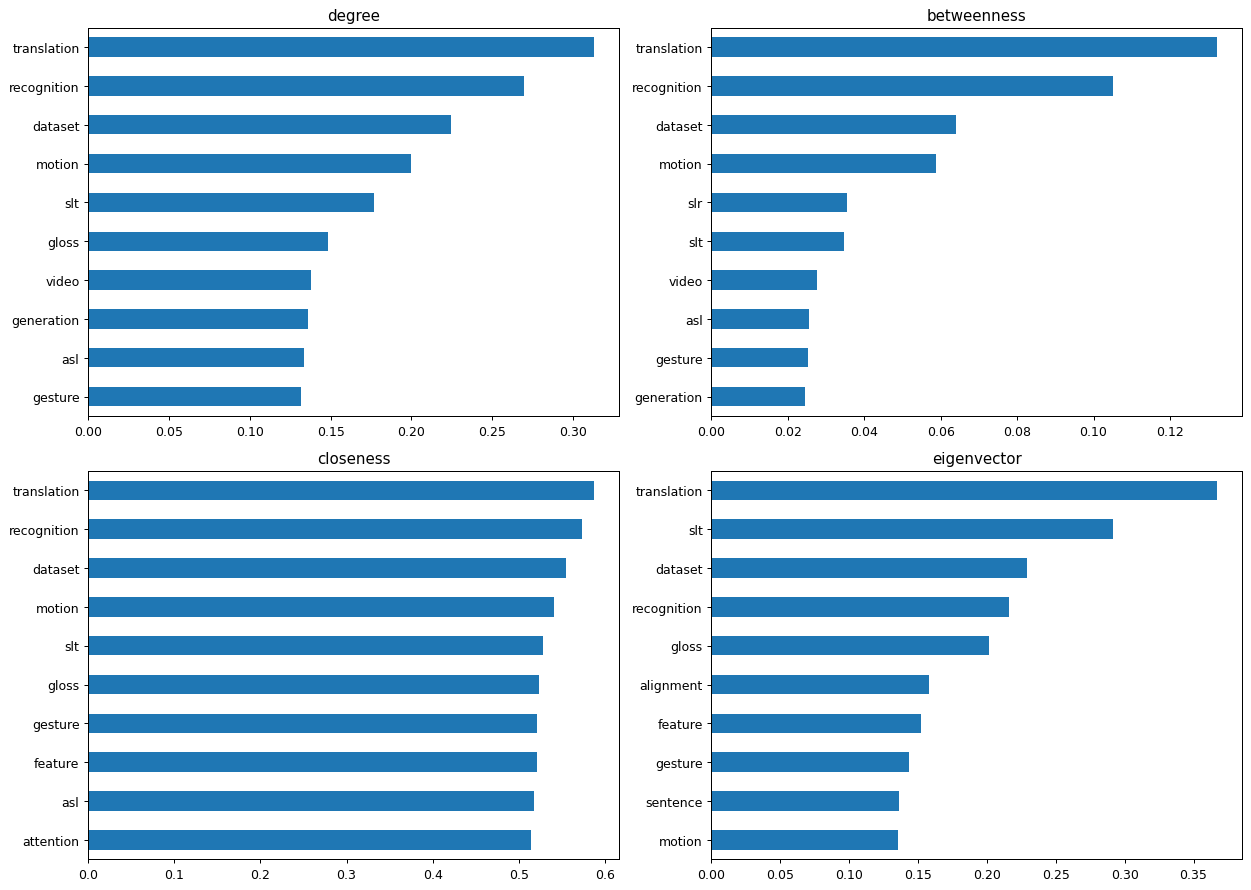

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, m in zip(axes.ravel(), centrality.columns):
    centrality[m].sort_values().tail(10).plot(kind="barh", ax=ax, title=m)
plt.tight_layout()
plt.show()

Во всех метриках на первом месте translation, дальше recognition и dataset: это основные направления — перевод, распознавание и сбор датасетов. По betweenness высоко стоят slr и asl — это слова-«мосты» между подтемами.

## 8. Граф публикаций

Вершины — статьи, ребро — есть общие ключевые слова, вес — сколько их.

In [18]:
kw_sets = [set(k) for k in df["keywords"]]
P = nx.Graph()
P.add_nodes_from(df.index)
for i, j in combinations(df.index, 2):
    common = len(kw_sets[i] & kw_sets[j])
    if common > 0:
        P.add_edge(i, j, weight=common)

print("Вершин:", P.number_of_nodes())
print("Рёбер:", P.number_of_edges())
print("Средняя степень:", round(np.mean([d for _, d in P.degree()]), 1))
print("Веса рёбер:", Counter(d["weight"] for _, _, d in P.edges(data=True)))

Вершин: 400
Рёбер: 8304
Средняя степень: 41.5
Веса рёбер: Counter({1: 7702, 2: 542, 3: 57, 4: 2, 6: 1})


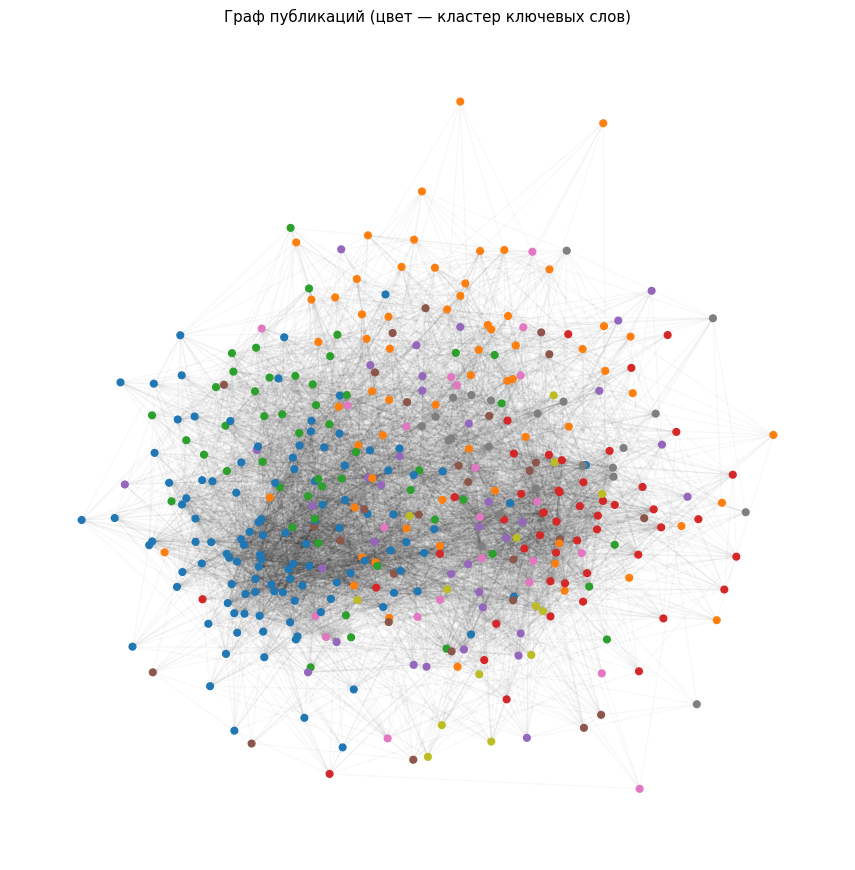

In [19]:
# цвет статьи — кластер, к которому относится больше всего её ключевых слов
paper_cluster = [Counter(cluster_of[k] for k in kws if k in cluster_of).most_common(1)[0][0]
                 if any(k in cluster_of for k in kws) else 0 for kws in df["keywords"]]
pos_p = nx.spring_layout(P, weight="weight", seed=42)
plt.figure(figsize=(12, 12))
nx.draw_networkx_edges(P, pos_p, alpha=0.03)
nx.draw_networkx_nodes(P, pos_p, node_size=30, node_color=[colors[c] for c in paper_cluster])
plt.title("Граф публикаций (цвет — кластер ключевых слов)")
plt.axis("off")
plt.show()

Поиск похожих статей делаю через Personalized PageRank: случайное блуждание по графу, которое всё время возвращается к исходной статье. Так учитываются не только прямые соседи, но и соседи соседей.

In [20]:
def similar_papers(i, top_n=10):
    scores = pd.Series(nx.pagerank(P, alpha=0.5, personalization={i: 1}, weight="weight"))
    scores = scores.drop(i).sort_values(ascending=False).head(top_n)
    print(df.at[i, "title"], df.at[i, "keywords"])
    return pd.DataFrame({
        "score": scores.round(4),
        "общих слов": [len(kw_sets[i] & kw_sets[j]) for j in scores.index],
        "шагов": [nx.shortest_path_length(P, i, j) for j in scores.index],
        "title": df.loc[scores.index, "title"],
    })


similar_papers(0)

PHOSA: Photorealistic 3D Sign Avatar Modeling and Benchmark ['avatar', 'hand', 'gesture', 'modeling', 'body', 'annotation']


,score,общих слов,шагов,title
72,0.0175,4,1,Tamaththul3D: High-Fidelity 3D Saudi Sign Language Avatars from Monocular Video
329,0.0105,2,1,One-Stage-TFS: Thai One-Stage Fingerspelling Dataset for Fingerspelling Recognition Frameworks
97,0.0101,2,1,Dynamic LIBRAS Gesture Recognition via CNN over Spatiotemporal Matrix Representation
372,0.0099,2,1,An Advanced Deep Learning Based Three-Stream Hybrid Model for Dynamic Hand Gesture Recognition
103,0.0098,2,1,Gesture-Aware Pretraining and Token Fusion for 3D Hand Pose Estimation
122,0.0096,2,1,VGG Induced Deep Hand Sign Language Detection
125,0.0094,2,1,DexAvatar: 3D Sign Language Reconstruction with Hand and Body Pose Priors
387,0.0058,1,1,Sign Language Recognition Based On Facial Expression and Hand Skeleton
292,0.0057,1,1,Survey on Hand Gesture Recognition from Visual Input
361,0.0055,1,1,Bengali Sign Language Recognition through Hand Pose Estimation using Multi-Branch Spatial-Temporal Attention Model


Для статьи про 3D-аватары на первом месте Tamaththul3D (тоже 3D-аватары, 4 общих слова), дальше статьи про руки и жесты, в том числе DexAvatar.

## 9. Поиск по запросу и тесты

Из запроса достаём ключевые слова так же, как из статей, и запускаем то же блуждание из статей, где эти слова есть (редкие слова запроса весят больше).

In [21]:
idf = dict(zip(terms, vectorizer.idf_))


def search(query, top_n=10):
    query_terms = set(ngrams(preprocess(query)))
    # вес стартовой статьи — сумма idf совпавших слов: редкие слова запроса важнее частых
    seeds = {i: sum(idf[t] for t in query_terms & kw_sets[i]) for i in df.index if query_terms & kw_sets[i]}
    print("Слова запроса:", sorted(query_terms & set(keyword_counts)), "; статей с ними:", len(seeds))
    scores = pd.Series(nx.pagerank(P, alpha=0.5, personalization=seeds, weight="weight"))
    scores = scores.sort_values(ascending=False).head(top_n)
    return pd.DataFrame({
        "score": scores.round(4),
        "есть слово запроса": [i in seeds for i in scores.index],
        "title": df.loc[scores.index, "title"],
    })

In [22]:
search("sign language translation with large language models (LLM)")

Слова запроса: ['llm', 'translation'] ; статей с ними: 61


,score,есть слово запроса,title
388,0.0255,True,Gloss2Text: Sign Language Gloss translation using LLMs and Semantically Aware Label Smoothing
322,0.0254,True,Enhanced Sign Language Translation between American Sign Language (ASL) and Indian Sign Language (ISL) Using LLMs
364,0.0251,True,An Efficient Sign Language Translation Using Spatial Configuration and Motion Dynamics with LLMs
150,0.0250,True,Large Sign Language Models: Toward 3D American Sign Language Translation
34,0.0163,True,DualAnchor: Preserving Language Priors and Improving Lexical Fidelity in Gloss-Free Sign Language Translation
302,0.0161,True,LLaVA-SLT: Visual Language Tuning for Sign Language Translation
47,0.0155,True,ViPo-MLLM: Visual-Pose Multimodal LLM for Gloss-Free Sign Language Translation
102,0.0155,True,SignAgent: Agentic LLMs for Linguistically-Grounded Sign Language Annotation and Dataset Curation
28,0.0152,True,SignLlama: Enhancing Gloss-free Sign Language Translation by Prioritizing Visual Features for LLMs
255,0.0152,True,Generative Sign-description Prompts with Multi-positive Contrastive Learning for Sign Language Recognition


In [23]:
search("3D avatar animation")

Слова запроса: ['animation', 'avatar'] ; статей с ними: 15


,score,есть слово запроса,title
221,0.0717,True,VisualSpeaker: Visually-Guided 3D Avatar Lip Synthesis
204,0.0713,True,"Evaluation of a Sign Language Avatar on Comprehensibility, User Experience \& Acceptability"
146,0.0404,True,IsharaKotha: A Comprehensive Avatar-based Bangla Sign Language Corpus
220,0.0393,True,Speak2Sign3D: A Multi-modal Pipeline for English Speech to American Sign Language Animation
67,0.0384,True,KAN Text to Vision? The Exploration of Kolmogorov-Arnold Networks for Multi-Scale Sequence-Based Pose Animation from Sign Language Notation
231,0.0382,True,Human-Centered Editable Speech-to-Sign-Language Generation via Streaming Conformer-Transformer and Resampling Hook
213,0.0365,True,MMS Player: an open source software for parametric data-driven animation of Sign Language avatars
73,0.0363,True,Low Resource Multimodal Translation of Nepali Spoken Words into Emotion-Conditioned Sign Language Avatars
0,0.0356,True,PHOSA: Photorealistic 3D Sign Avatar Modeling and Benchmark
72,0.0351,True,Tamaththul3D: High-Fidelity 3D Saudi Sign Language Avatars from Monocular Video


In [24]:
search("Bangla sign language recognition")

Слова запроса: ['bangla', 'recognition'] ; статей с ними: 47


,score,есть слово запроса,title
151,0.0269,True,Introducing A Bangla Sentence - Gloss Pair Dataset for Bangla Sign Language Translation and Research
365,0.0269,True,BAUST Lipi: A BdSL Dataset with Deep Learning Based Bangla Sign Language Recognition
196,0.0262,True,Continuous Bangla Sign Language Translation: Mitigating the Expense of Gloss Annotation with the Assistance of Graph
146,0.0258,True,IsharaKotha: A Comprehensive Avatar-based Bangla Sign Language Corpus
282,0.0256,True,BdSLW401: Transformer-Based Word-Level Bangla Sign Language Recognition Using Relative Quantization Encoding (RQE)
29,0.0255,True,Toward Deployable Bangla Sign Language Recognition with Expert-Validated Data and a Lightweight Attention-Based Model
303,0.0247,True,Real-time Bangla Sign Language Translator
329,0.0148,True,One-Stage-TFS: Thai One-Stage Fingerspelling Dataset for Fingerspelling Recognition Frameworks
165,0.0144,True,Real-Time Sign Language to text Translation using Deep Learning: A Comparative study of LSTM and 3D CNN
166,0.0144,True,Nepali Sign Language Characters Recognition: Dataset Development and Deep Learning Approaches


In [25]:
search("question answering")

Слова запроса: ['question'] ; статей с ними: 3


,score,есть слово запроса,title
174,0.1770,True,SSL-SSAW: Self-Supervised Learning with Sigmoid Self-Attention Weighting for Question-Based Sign Language Translation
338,0.1765,True,BQA: Body Language Question Answering Dataset for Video Large Language Models
33,0.1721,True,"Sign Language Question Answering: A New Task, Benchmark, and Baseline for Sign Language Understanding"
60,0.0185,False,SLU-2K: A Question-Based Benchmark for Semantic Evaluation of Sign Language Translation
371,0.0152,False,Scaling up Multimodal Pre-training for Sign Language Understanding
50,0.0096,False,SIGNET: Motion-Level Knowledge Transfer for Cross-Language Sign Language Translation
172,0.0091,False,Sigma: Semantically Informative Pre-training for Skeleton-based Sign Language Understanding
27,0.0088,False,Bridging the Gap Between Semantics and Reconstruction:Unifying Sign Language Translation and Production
291,0.0085,False,Uni-Sign: Toward Unified Sign Language Understanding at Scale
191,0.0076,False,Text-Driven 3D Hand Motion Generation from Sign Language Data


In [26]:
similar_papers(184)  # статья про робо-руку для алфавита ASL, у неё мало соседей

Low-Cost Open-Source Ambidextrous Robotic Hand with 23 Direct-Drive servos for American Sign Language Alphabet ['coverage', 'alphabet', 'file', 'license', 'wrist', 'communication technology']


,score,общих слов,шагов,title
255,0.0455,1,1,Generative Sign-description Prompts with Multi-positive Contrastive Learning for Sign Language Recognition
343,0.0455,1,1,Advanced Arabic Alphabet Sign Language Recognition Using Transfer Learning and Transformer Models
339,0.0438,1,1,Bukva: Russian Sign Language Alphabet
20,0.0435,1,1,JSL-DC: A Word-Level Japanese Sign Language Dataset with Linguist-Derived Descriptions for Distinguishing Confusable Signs
294,0.0434,1,1,Revolutionizing Communication with Deep Learning and XAI for Enhanced Arabic Sign Language Recognition
203,0.0425,1,1,The TUB Sign Language Corpus Collection
166,0.0048,0,2,Nepali Sign Language Characters Recognition: Dataset Development and Deep Learning Approaches
120,0.0042,0,2,Arabic Sign Language Recognition using Multimodal Approach
148,0.0034,0,2,RoCoISLR: A Romanian Corpus for Isolated Sign Language Recognition
181,0.0032,0,2,SSL-SLR: Self-Supervised Representation Learning for Sign Language Recognition


Поиск работает: по LLM и переводу находятся статьи про перевод с помощью LLM, по аватарам — про аватары, по Bangla — статьи про бенгальский жестовый язык.

Для "question answering" прямых совпадений всего 3, остальные статьи найдены через граф: слова question у них нет, но они про понимание жестового языка. Для статьи про робо-руку после 6 прямых соседей идут статьи в 2 шагах — тоже про распознавание алфавитов и жестов разных языков (непальский, арабский, румынский корпус).

Простая автоматическая проверка: доля найденных статей из того же кластера, что и запрос, по сравнению со случайной выдачей.

In [27]:
rng = np.random.default_rng(42)
graph_hits, random_hits = [], []
for i in df.index:
    scores = pd.Series(nx.pagerank(P, alpha=0.5, personalization={i: 1}, weight="weight")).drop(i)
    found = scores.sort_values(ascending=False).index[:5]
    graph_hits.append(np.mean([paper_cluster[j] == paper_cluster[i] for j in found]))
    random_hits.append(np.mean([paper_cluster[j] == paper_cluster[i] for j in rng.choice(len(df), 5)]))
print("поиск по графу:", round(np.mean(graph_hits), 2), "; случайно:", round(np.mean(random_hits), 2))

поиск по графу: 0.53 ; случайно: 0.16


53% против 16%: поиск по графу примерно в 3 раза лучше случайной выдачи